In [3]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split

# Import fungsi buatan sendiri dari file .py di folder yang sama
from A_eda_pipeline import quick_eda, build_preprocessing_pipeline
from B_benchmark_eval import benchmark_models, evaluate_best_model

# Load dataset dari penguji
df = pd.read_csv('z_dataset_peserta.csv')
df.head()

,user_id,age,tenure_months,monthly_spend,gender,subscription_type,payment_method,churn
0,USR001,56,8,90.50,NaN,VIP,Bank Transfer,0
1,USR002,46,24,159.23,NaN,Basic,E-Wallet,1
2,USR003,32,11,104.25,Male,Premium,Bank Transfer,1
3,USR004,60,17,99.76,Male,Premium,Bank Transfer,0
4,USR005,25,8,30.33,NaN,Basic,E-Wallet,0


=== DATA OVERVIEW ===
Shape: 103 rows, 8 columns

                     Dtype  Missing Values  Missing (%)  Unique Values
user_id             object               0         0.00            100
age                  int64               0         0.00             43
tenure_months        int64               0         0.00             39
monthly_spend      float64               5         4.85             95
gender              object              13        12.62              2
subscription_type   object               0         0.00              3
payment_method      object               0         0.00              3
churn                int64               0         0.00              2

Total Duplicate Rows: 3

=== TARGET DISTRIBUTION (churn) ===
       Count  Percentage (%)
churn                       
0         72            69.9
1         31            30.1


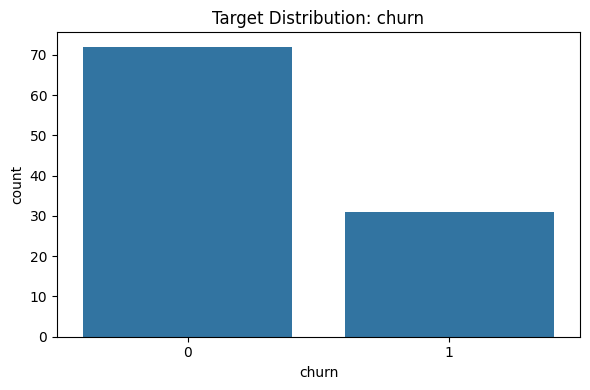

In [4]:
# Cek missing value, duplikat, & distribusi target (misal kolom target = 'churn')
quick_eda(df, target_col='churn')

In [5]:
# Pisahkan fitur (X) dan target (y)
X = df.drop(columns=['churn', 'user_id']) # Buang kolom ID/Target
y = df['churn']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Jalankan pipeline preprocessing otomatis
preprocessor = build_preprocessing_pipeline(X_train)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

Numeric Columns (3): ['age', 'tenure_months', 'monthly_spend']
Categorical Columns (3): ['gender', 'subscription_type', 'payment_method']


In [6]:
# Melatih 5 model sekaligus dalam sekali jalan
summary_df, trained_models = benchmark_models(X_train_prep, y_train, X_test_prep, y_test)

# Tampilkan tabel hasil performa model
summary_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,Random Forest,0.666667,0.683673,0.666667,0.673740,0.666667,0.103
1,LightGBM,0.714286,0.669173,0.714286,0.659664,0.555556,1.409
2,XGBoost,0.666667,0.650000,0.666667,0.656891,0.611111,0.064
3,Logistic Regression,0.714286,0.510204,0.714286,0.595238,0.644444,0.017
4,Decision Tree,0.476190,0.539683,0.476190,0.499471,0.433333,0.007


=== CLASSIFICATION REPORT: LightGBM ===
              precision    recall  f1-score   support

           0       0.74      0.93      0.82        15
           1       0.50      0.17      0.25         6

    accuracy                           0.71        21
   macro avg       0.62      0.55      0.54        21
weighted avg       0.67      0.71      0.66        21



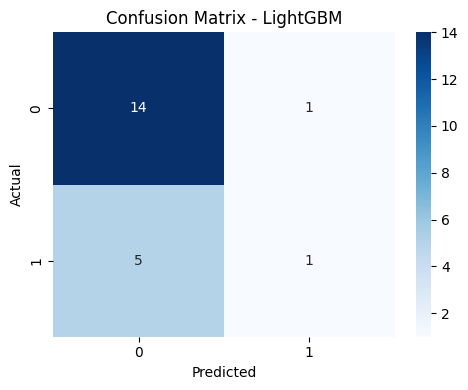

Model berhasil disimpan ke best_pipeline.joblib!


In [7]:
# Ambil model terbaik berdasarkan F1-Score (misal LightGBM)
best_model = trained_models['LightGBM']

# Tampilkan Classification Report & Confusion Matrix
evaluate_best_model(best_model, X_test_prep, y_test, model_name="LightGBM")

# Gabungkan preprocessor + model jadi 1 file .joblib utuh
from sklearn.pipeline import Pipeline
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', best_model)
])

joblib.dump(full_pipeline, 'best_pipeline.joblib')
print("Model berhasil disimpan ke best_pipeline.joblib!")